
image 1/1 /Users/macbook/Desktop/dental-ai-datasets/notebooks/../datasets/X-rays/test/cavities/101.jpg: 320x640 1 person, 1 sports ball, 190.4ms
Speed: 3.4ms preprocess, 190.4ms inference, 2.4ms postprocess per image at shape (1, 3, 320, 640)
Saved image path: predictions/101.jpg


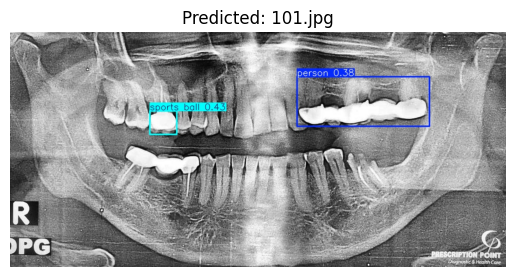


image 1/1 /Users/macbook/Desktop/dental-ai-datasets/notebooks/../datasets/X-rays/test/cavities/115.jpg: 352x640 (no detections), 336.8ms
Speed: 4.8ms preprocess, 336.8ms inference, 1.0ms postprocess per image at shape (1, 3, 352, 640)
Saved image path: predictions/115.jpg


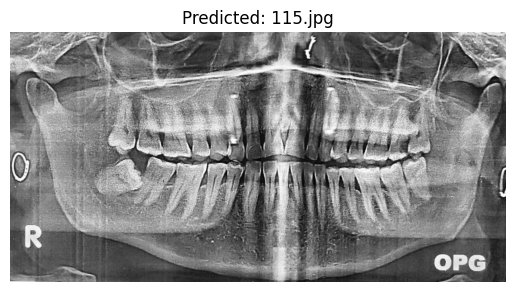


image 1/1 /Users/macbook/Desktop/dental-ai-datasets/notebooks/../datasets/X-rays/test/cavities/100.jpg: 352x640 (no detections), 203.8ms
Speed: 12.6ms preprocess, 203.8ms inference, 0.9ms postprocess per image at shape (1, 3, 352, 640)
Saved image path: predictions/100.jpg


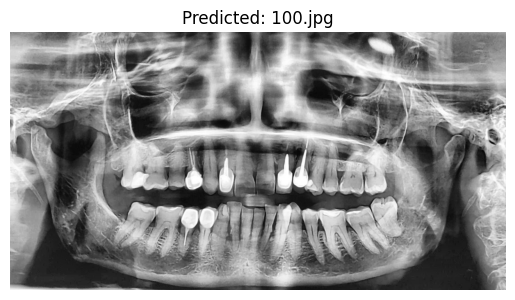

In [6]:
# 1. Imports
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

# 2. Load the model
model = YOLO('yolov8n.pt')  # You can use yolov8s.pt for better accuracy

# 3. Set your image path
image_dir = '../datasets/X-rays/test/cavities'
image_files = [f for f in os.listdir(image_dir) if f.endswith(('.jpg', '.jpeg', '.png'))][:3]

# 4. Create a folder to save predictions
save_dir = "predictions"
os.makedirs(save_dir, exist_ok=True)

# 5. Run detection and save images
for image_file in image_files:
    img_path = os.path.join(image_dir, image_file)

    # Run detection
    results = model(img_path)

    # Get annotated image
    annotated_img = results[0].plot()

    # Save the image in the predictions folder only
    save_path = os.path.join(save_dir, image_file)
    cv2.imwrite(save_path, annotated_img)

    print("Saved image path:", save_path)

    # Display the image using matplotlib
    img_result = cv2.imread(save_path)
    if img_result is None:
        print("Failed to load saved image!")
        continue

    img_result = cv2.cvtColor(img_result, cv2.COLOR_BGR2RGB)
    plt.imshow(img_result)
    plt.title(f"Predicted: {image_file}")
    plt.axis('off')
    plt.show()
